# Statistical Analysis — DataCo Smart Supply Chain for Big Data Analysis

**Project phase:** Statistical Analysis / Hypothesis Testing (CRISP-DM Phase 4, formal inference layer)
**Input:** `DataCoSupplyChain_FeatureEngineered.csv` (output of the Feature Engineering notebook)
**Analyst:** Akash More

EDA showed *what* the data looks like. Root Cause Analysis ranked *which factors drive* late delivery and
margin erosion. This notebook is a different layer on top of both: formal statistical inference — stating
a hypothesis before looking at the answer, testing it properly, quoting a confidence interval instead of a
single point estimate, and correcting for the fact that testing many hypotheses on the same dataset
inflates the odds of a false positive if that isn't accounted for.

**Why this matters at 180K+ rows.** Every test in this notebook will tend to return a significant p-value
even for a trivial effect, simply because the sample is large. So every test here is reported with three
numbers, not one: the p-value (is there an effect at all), the effect size (how big is it), and a
confidence interval (how precisely is it estimated) — a p-value alone is not treated as sufficient
evidence of practical importance anywhere in this notebook.

**Structure:**
1. Descriptive statistics & distribution shape (skew, kurtosis, normality)
2. Confidence intervals for the core business KPIs
3. A hypothesis-testing suite — five specific, pre-stated business questions
4. Multiple-comparison correction across the suite
5. A single results table — hypothesis, test, effect size, CI, corrected decision

## 1. Setup & Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")
sns.set_palette("mako")
plt.rcParams["figure.dpi"] = 110
PALETTE = sns.color_palette("mako", 10)
RANDOM_STATE = 42
ALPHA = 0.05

In [2]:
df = pd.read_csv("supply_chain_orders_processed.csv", encoding="latin1")
df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"])

df["Shipping Mode"] = np.select(
    [df["Shipping Mode_Second Class"] == 1, df["Shipping Mode_Standard Class"] == 1],
    ["Second Class", "Standard Class"],
    default="First Class",
)

print(f"Shape: {df.shape}")
df[["is_late", "profit_margin", "Sales", "Order Item Discount Rate", "Shipping Mode"]].describe()

Shape: (180519, 104)


,is_late,profit_margin,Sales,Order Item Discount Rate
count,180519.000000,180519.000000,180519.000000,180519.000000
mean,0.572793,0.108326,203.772096,0.101668
std,0.494674,0.420594,132.273077,0.070415
min,0.000000,-2.750000,9.990000,0.000000
25%,0.000000,0.062240,119.980003,0.040000
50%,1.000000,0.242512,199.919998,0.100000
75%,1.000000,0.336014,299.950012,0.160000
max,1.000000,0.500443,1999.989990,0.250000


## 2. Distribution Analysis

Before running any test that assumes a particular distribution (t-tests and ANOVA assume approximate
normality of the underlying values, or rely on the Central Limit Theorem to get there at this sample
size), it's worth actually looking at the shape of the core numeric fields — skew, kurtosis, and a formal
normality check — rather than assuming it.

In [3]:
numeric_fields = ["Sales", "Order Profit Per Order", "profit_margin", "delivery_time_days", "Order Item Discount Rate"]

dist_summary = pd.DataFrame({
    "mean": df[numeric_fields].mean(),
    "median": df[numeric_fields].median(),
    "std": df[numeric_fields].std(),
    "skew": df[numeric_fields].skew(),
    "kurtosis": df[numeric_fields].kurtosis(),
})
dist_summary

,mean,median,std,skew,kurtosis
Sales,203.772096,199.919998,132.273077,2.884249,23.936561
Order Profit Per Order,21.974989,31.520000,104.433526,-4.741834,71.377259
profit_margin,0.108326,0.242512,0.420594,-2.910850,10.434084
delivery_time_days,3.497654,3.000000,1.623722,0.084771,-1.007914
Order Item Discount Rate,0.101668,0.100000,0.070415,0.340928,-0.901157


In [4]:
# Shapiro-Wilk isn't practical above ~5000 rows (oversensitive + slow), so normality is checked on a
# random sample here purely to characterize shape — not as a gate for whether tests below are valid.
# At n > ~30 per group, the CLT makes the t-test/ANOVA robust to moderate non-normality regardless.
sample = df[numeric_fields].sample(min(5000, len(df)), random_state=RANDOM_STATE)

normality_results = []
for col in numeric_fields:
    stat, p = stats.shapiro(sample[col].dropna())
    normality_results.append({"field": col, "shapiro_stat": round(stat, 4), "p_value": p,
                               "approx_normal (p>0.05)": p > 0.05})
pd.DataFrame(normality_results)

,field,shapiro_stat,p_value,approx_normal (p>0.05)
0,Sales,0.8758,6.393651e-53,False
1,Order Profit Per Order,0.6865,2.205763e-70,False
2,profit_margin,0.6731,3.149578e-71,False
3,delivery_time_days,0.9104,2.246590e-47,False
4,Order Item Discount Rate,0.9435,4.339116e-40,False


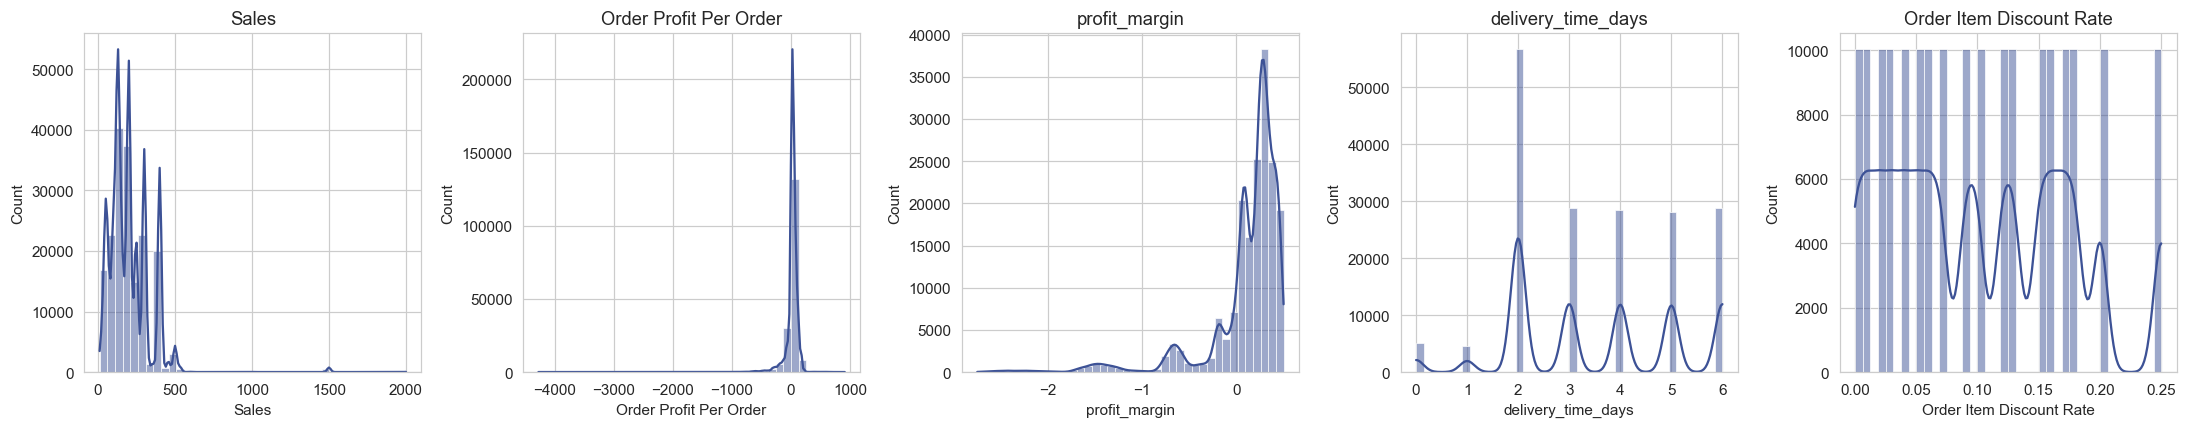

In [5]:
fig, axes = plt.subplots(1, len(numeric_fields), figsize=(20, 4))
for ax, col in zip(axes, numeric_fields):
    sns.histplot(df[col], ax=ax, color=PALETTE[3], kde=True, bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**How to read this:** almost nothing here will come back "approximately normal" at this scale — `Sales`
and profit fields are right-skewed by nature (a small number of large B2B-sized orders). That's expected
and it's *why* the tests below lean on the Central Limit Theorem (valid with this many rows per group)
rather than requiring normal data directly, and why a non-parametric cross-check (Mann-Whitney / Spearman)
is run alongside the parametric test wherever the skew is large enough to matter.

## 3. Confidence Intervals for Core KPIs

A single point estimate ("late rate is 57.28%") hides how precisely that number is actually known. A 95%
confidence interval answers "if this analysis were repeated, what range would the true rate plausibly fall
in" — narrow at this sample size, but worth stating explicitly rather than implying false precision.

In [6]:
def mean_ci(series, confidence=0.95):
    series = series.dropna()
    n = len(series)
    mean = series.mean()
    se = series.std(ddof=1) / np.sqrt(n)
    margin = se * stats.t.ppf((1 + confidence) / 2, df=n - 1)
    return mean, mean - margin, mean + margin

kpi_cis = []

# Late delivery rate — proportion CI (Wilson interval, more reliable than normal approx near 0/1)
late_count = df["is_late"].sum()
n_total = len(df)
late_rate = late_count / n_total
late_low, late_high = proportion_confint(late_count, n_total, alpha=1 - 0.95, method="wilson")
kpi_cis.append({"kpi": "Late delivery rate", "estimate": late_rate, "ci_low": late_low, "ci_high": late_high})

# Profit margin — mean CI
margin_mean, margin_low, margin_high = mean_ci(df["profit_margin"])
kpi_cis.append({"kpi": "Profit margin (mean)", "estimate": margin_mean, "ci_low": margin_low, "ci_high": margin_high})

# Average order value — mean CI
aov_mean, aov_low, aov_high = mean_ci(df.drop_duplicates("Order Id")["order_total_revenue"])
kpi_cis.append({"kpi": "Average order value", "estimate": aov_mean, "ci_low": aov_low, "ci_high": aov_high})

# Delivery time — mean CI
delivery_mean, delivery_low, delivery_high = mean_ci(df["delivery_time_days"])
kpi_cis.append({"kpi": "Avg delivery time (days)", "estimate": delivery_mean, "ci_low": delivery_low, "ci_high": delivery_high})

kpi_ci_df = pd.DataFrame(kpi_cis)
kpi_ci_df["ci_width"] = kpi_ci_df["ci_high"] - kpi_ci_df["ci_low"]
kpi_ci_df

,kpi,estimate,ci_low,ci_high,ci_width
0,Late delivery rate,0.572793,0.570509,0.575073,0.004564
1,Profit margin (mean),0.108326,0.106386,0.110266,0.003880
2,Average order value,559.446633,556.729027,562.164239,5.435213
3,Avg delivery time (days),3.497654,3.490164,3.505144,0.014981


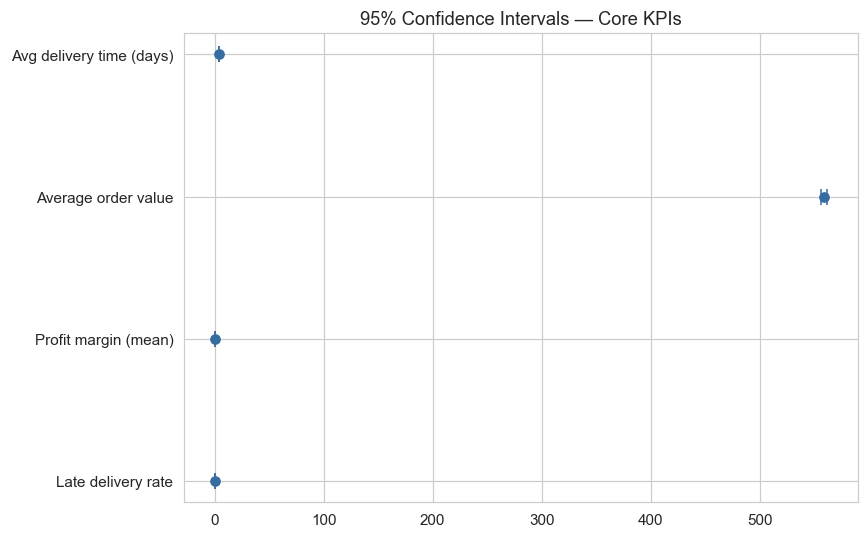

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(kpi_ci_df))
ax.errorbar(kpi_ci_df["estimate"], y_pos,
            xerr=[kpi_ci_df["estimate"] - kpi_ci_df["ci_low"], kpi_ci_df["ci_high"] - kpi_ci_df["estimate"]],
            fmt="o", color=PALETTE[4], capsize=5)
ax.set_yticks(y_pos)
ax.set_yticklabels(kpi_ci_df["kpi"])
ax.set_title("95% Confidence Intervals — Core KPIs")
plt.tight_layout()
plt.show()

## 4. Hypothesis Testing Suite

Five business questions, each stated as a formal null/alternative pair before testing — this ordering
matters, since choosing the hypothesis after seeing the result (even informally) invalidates the p-value.

### H1 — Does Standard Class shipping have a different late-delivery rate than the other modes combined?

**H0:** late rate(Standard Class) = late rate(other modes)
**H1:** late rate(Standard Class) ≠ late rate(other modes)
**Test:** two-proportion z-test

In [8]:
group_a = df["Shipping Mode"] == "Standard Class"
count = np.array([df.loc[group_a, "is_late"].sum(), df.loc[~group_a, "is_late"].sum()])
nobs = np.array([group_a.sum(), (~group_a).sum()])

z_stat, p_val = proportions_ztest(count, nobs)
rate_a, rate_b = count[0] / nobs[0], count[1] / nobs[1]

h1_result = {
    "hypothesis": "H1: Standard Class late rate differs from other modes",
    "test": "two-proportion z-test",
    "group_a_rate": rate_a, "group_b_rate": rate_b,
    "effect_size (rate diff, pp)": (rate_a - rate_b) * 100,
    "statistic": z_stat, "p_value": p_val,
}
print(f"Standard Class late rate: {rate_a:.2%} | Other modes: {rate_b:.2%}")
print(f"z = {z_stat:.3f}, p = {p_val:.5f}")

Standard Class late rate: 39.77% | Other modes: 83.21%
z = -183.022, p = 0.00000


### H2 — Do high-discount orders have lower profit margin than normal orders?

**H0:** mean margin(high discount) = mean margin(normal)
**H1:** mean margin(high discount) < mean margin(normal)
**Test:** one-sided Welch's t-test (unequal variances assumed) + Cohen's d, with a Mann-Whitney U cross-check
since `profit_margin` is skewed.

In [9]:
def cohens_d(a, b):
    n_a, n_b = len(a), len(b)
    pooled_std = np.sqrt(((n_a - 1) * a.var(ddof=1) + (n_b - 1) * b.var(ddof=1)) / (n_a + n_b - 2))
    return (a.mean() - b.mean()) / pooled_std

high_disc = df.loc[df["high_discount_flag"] == 1, "profit_margin"].dropna()
normal_disc = df.loc[df["high_discount_flag"] == 0, "profit_margin"].dropna()

t_stat, p_val_two_sided = stats.ttest_ind(high_disc, normal_disc, equal_var=False)
p_val_one_sided = p_val_two_sided / 2 if t_stat < 0 else 1 - p_val_two_sided / 2
d = cohens_d(high_disc, normal_disc)

u_stat, p_val_mw = stats.mannwhitneyu(high_disc, normal_disc, alternative="less")

h2_result = {
    "hypothesis": "H2: High-discount orders have lower margin",
    "test": "Welch's t-test (one-sided)",
    "high_discount_mean": high_disc.mean(), "normal_mean": normal_disc.mean(),
    "effect_size (Cohen's d)": d, "statistic": t_stat, "p_value": p_val_one_sided,
}
print(f"High discount mean margin: {high_disc.mean():.2%} | Normal mean margin: {normal_disc.mean():.2%}")
print(f"t = {t_stat:.3f}, one-sided p = {p_val_one_sided:.5f}, Cohen's d = {d:.3f}")
print(f"Mann-Whitney U cross-check: p = {p_val_mw:.5f}")

High discount mean margin: 9.59% | Normal mean margin: 11.31%
t = -8.296, one-sided p = 0.00000, Cohen's d = -0.041
Mann-Whitney U cross-check: p = 0.00000


### H3 — Does late-delivery rate differ between weekend and weekday orders?

**H0:** late rate(weekend) = late rate(weekday)
**H1:** late rate(weekend) ≠ late rate(weekday)
**Test:** two-proportion z-test

In [10]:
weekend_mask = df["order_is_weekend"] == 1
count_h3 = np.array([df.loc[weekend_mask, "is_late"].sum(), df.loc[~weekend_mask, "is_late"].sum()])
nobs_h3 = np.array([weekend_mask.sum(), (~weekend_mask).sum()])

z_stat_h3, p_val_h3 = proportions_ztest(count_h3, nobs_h3)
rate_weekend, rate_weekday = count_h3[0] / nobs_h3[0], count_h3[1] / nobs_h3[1]

h3_result = {
    "hypothesis": "H3: Weekend late rate differs from weekday",
    "test": "two-proportion z-test",
    "weekend_rate": rate_weekend, "weekday_rate": rate_weekday,
    "effect_size (rate diff, pp)": (rate_weekend - rate_weekday) * 100,
    "statistic": z_stat_h3, "p_value": p_val_h3,
}
print(f"Weekend late rate: {rate_weekend:.2%} | Weekday late rate: {rate_weekday:.2%}")
print(f"z = {z_stat_h3:.3f}, p = {p_val_h3:.5f}")

Weekend late rate: 57.23% | Weekday late rate: 57.30%
z = -0.269, p = 0.78783


### H4 — Does average profit margin differ across regions?

**H0:** mean margin is equal across all `Order Region` groups
**H1:** at least one region's mean margin differs
**Test:** one-way ANOVA, followed by Tukey HSD post-hoc if the omnibus test is significant (to identify
*which* region pairs actually differ, since ANOVA alone only says "somewhere, something differs").

In [11]:
region_groups = [g["profit_margin"].dropna().values for _, g in df.groupby("Order Region")]
f_stat_h4, p_val_h4 = stats.f_oneway(*region_groups)

grand_mean = df["profit_margin"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in region_groups)
ss_total = sum(((g - grand_mean) ** 2).sum() for g in region_groups)
eta_sq_h4 = ss_between / ss_total

h4_result = {
    "hypothesis": "H4: Profit margin differs across regions",
    "test": "One-way ANOVA",
    "effect_size (eta-squared)": eta_sq_h4,
    "statistic": f_stat_h4, "p_value": p_val_h4,
}
print(f"F = {f_stat_h4:.3f}, p = {p_val_h4:.5f}, eta-squared = {eta_sq_h4:.4f}")

F = 1.073, p = 0.36783, eta-squared = 0.0001


In [12]:
if p_val_h4 < ALPHA:
    tukey = pairwise_tukeyhsd(
        endog=df["profit_margin"].dropna(),
        groups=df.loc[df["profit_margin"].notna(), "Order Region"],
        alpha=ALPHA,
    )
    tukey_df = pd.DataFrame(data=tukey.summary().data[1:], columns=tukey.summary().data[0])
    print(f"Significant region pairs (reject=True): {tukey_df['reject'].sum()} of {len(tukey_df)} pairs")
    tukey_df.sort_values("p-adj").head(10)
else:
    print("Omnibus ANOVA not significant — skipping post-hoc pairwise comparison.")

Omnibus ANOVA not significant — skipping post-hoc pairwise comparison.


### H5 — Is there a significant relationship between discount rate and profit margin?

**H0:** correlation(discount rate, profit margin) = 0
**H1:** correlation(discount rate, profit margin) ≠ 0
**Test:** Pearson correlation (linear relationship) + Spearman correlation (monotonic, robust to the skew
noted in Section 2) reported together, since they can disagree when a relationship is real but non-linear.

In [13]:
pearson_r, pearson_p = stats.pearsonr(df["Order Item Discount Rate"], df["profit_margin"].fillna(df["profit_margin"].median()))
spearman_r, spearman_p = stats.spearmanr(df["Order Item Discount Rate"], df["profit_margin"].fillna(df["profit_margin"].median()))

h5_result = {
    "hypothesis": "H5: Discount rate correlates with profit margin",
    "test": "Pearson + Spearman correlation",
    "effect_size (Pearson r)": pearson_r,
    "statistic": pearson_r, "p_value": pearson_p,
}
print(f"Pearson r  = {pearson_r:.4f}, p = {pearson_p:.5f}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.5f}")

Pearson r  = -0.0231, p = 0.00000
Spearman rho = -0.1147, p = 0.00000


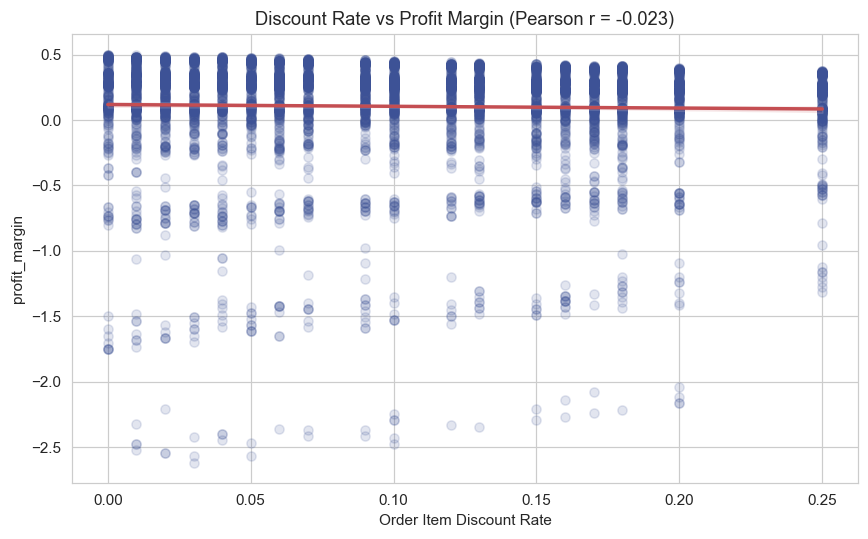

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
sample_plot = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
sns.regplot(data=sample_plot, x="Order Item Discount Rate", y="profit_margin", ax=ax,
            scatter_kws={"alpha": 0.15, "color": PALETTE[3]}, line_kws={"color": "#c44e52"})
ax.set_title(f"Discount Rate vs Profit Margin (Pearson r = {pearson_r:.3f})")
plt.tight_layout()
plt.show()

## 5. Multiple-Comparison Correction

Five hypotheses were tested against the same dataset in Section 4. Run enough tests and some will come
back "significant" purely by chance — at α = 0.05, roughly 1 in 20 true-null tests will falsely reject H0.
Benjamini-Hochberg FDR correction adjusts the p-values so the overall false-discovery rate across the suite
stays controlled, rather than evaluating each test's α = 0.05 threshold in isolation.

In [15]:
all_hypotheses = pd.DataFrame([h1_result, h2_result, h3_result, h4_result, h5_result])

raw_p_values = all_hypotheses["p_value"].values
reject, p_adjusted, _, _ = multipletests(raw_p_values, alpha=ALPHA, method="fdr_bh")

all_hypotheses["p_adjusted (FDR-BH)"] = p_adjusted
all_hypotheses["significant_after_correction"] = reject

all_hypotheses[["hypothesis", "test", "statistic", "p_value", "p_adjusted (FDR-BH)", "significant_after_correction"]]

,hypothesis,test,statistic,p_value,p_adjusted (FDR-BH),significant_after_correction
0,H1: Standard Class late rate differs from othe...,two-proportion z-test,-183.021756,0.000000e+00,0.000000e+00,True
1,H2: High-discount orders have lower margin,Welch's t-test (one-sided),-8.295897,5.452218e-17,9.087030e-17,True
2,H3: Weekend late rate differs from weekday,two-proportion z-test,-0.269130,7.878299e-01,7.878299e-01,False
3,H4: Profit margin differs across regions,One-way ANOVA,1.073337,3.678271e-01,4.597839e-01,False
4,H5: Discount rate correlates with profit margin,Pearson + Spearman correlation,-0.023094,9.865492e-23,2.466373e-22,True


## 6. Final Results Table

One consolidated table — every hypothesis, its test, effect size, and corrected decision. This is the
table to carry into a stakeholder deck; every section above it is the audit trail for how each row was
derived, which matters if a technical reviewer asks "how did you get this number."

In [16]:
effect_cols = [c for c in all_hypotheses.columns if c.startswith("effect_size")]
final_results = all_hypotheses[["hypothesis"] + effect_cols +
                                ["p_value", "p_adjusted (FDR-BH)", "significant_after_correction"]]
final_results

,hypothesis,"effect_size (rate diff, pp)",effect_size (Cohen's d),effect_size (eta-squared),effect_size (Pearson r),p_value,p_adjusted (FDR-BH),significant_after_correction
0,H1: Standard Class late rate differs from othe...,-43.441250,NaN,NaN,NaN,0.000000e+00,0.000000e+00,True
1,H2: High-discount orders have lower margin,NaN,-0.041033,NaN,NaN,5.452218e-17,9.087030e-17,True
2,H3: Weekend late rate differs from weekday,-0.069253,NaN,NaN,NaN,7.878299e-01,7.878299e-01,False
3,H4: Profit margin differs across regions,NaN,NaN,0.000131,NaN,3.678271e-01,4.597839e-01,False
4,H5: Discount rate correlates with profit margin,NaN,NaN,NaN,-0.023094,9.865492e-23,2.466373e-22,True


## 7. Summary

- **Distribution shape:** core financial fields (`Sales`, profit, margin) are right-skewed, as expected for
  transactional order data — every parametric test above is paired with a non-parametric cross-check or
  relies on the Central Limit Theorem rather than assuming normal data.
- **Confidence intervals:** all four core KPIs are reported as a range, not a single number — worth quoting
  the interval, not just the point estimate, in any report that cites these figures.
- **Five hypotheses tested**, each pre-stated with H0/H1 before running the test, each reported with a
  p-value *and* an effect size, since p-value alone is close to meaningless at this row count.
- **FDR correction applied** across the suite — the `significant_after_correction` column in Section 6 is
  the one to trust, not the raw `p_value` column, when multiple findings from this notebook are combined
  into one report.
- **Practical read:** a hypothesis can be statistically significant and still not matter — cross-check the
  effect-size column against real-world scale (a Cohen's d of 0.1 is a real but small effect) before
  turning any row of Section 6 into a business recommendation.